# HeartSense: exploratory data analysis

UCI Heart Disease, Cleveland subset (303 patients, 13 clinical measurements, binary outcome).
This notebook is generated by `scripts/build_notebook.py` and uses the same functions as
`python -m heartsense.explore`, so the figures here are exactly the ones in `reports/figures/eda/`.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
import pandas as pd
from IPython.display import Image, display
from heartsense import settings as cfg
from heartsense.ingest import load_clean, summary
from heartsense import explore

pd.set_option("display.width", 140)
df = load_clean()
summary(df)

{'rows': 303,
 'columns': 14,
 'positive_rate': 0.4587,
 'missing_cells': 6,
 'missing_by_column': {'major_vessels': 4, 'thalassemia': 2}}

## 1. Schema and a first look
Descriptive names replace the UCI abbreviations; `target` = 1 when the original `num` diagnosis is > 0.

In [2]:
df.head(8)

,age,resting_bp,cholesterol,max_heart_rate,st_depression,major_vessels,sex,fasting_blood_sugar,exercise_angina,chest_pain_type,rest_ecg,st_slope,thalassemia,target
0,63,145.0,233.0,150.0,2.3,0,1,1,0,1,2,3,6,0
1,67,160.0,286.0,108.0,1.5,3,1,0,1,4,2,2,3,1
2,67,120.0,229.0,129.0,2.6,2,1,0,1,4,2,2,7,1
3,37,130.0,250.0,187.0,3.5,0,1,0,0,3,0,3,3,0
4,41,130.0,204.0,172.0,1.4,0,0,0,0,2,2,1,3,0
5,56,120.0,236.0,178.0,0.8,0,1,0,0,2,0,1,3,0
6,62,140.0,268.0,160.0,3.6,2,0,0,0,4,2,3,3,1
7,57,120.0,354.0,163.0,0.6,0,0,0,1,4,0,1,3,0


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
resting_bp,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
cholesterol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
max_heart_rate,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
st_depression,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2
major_vessels,299.0,0.672241,0.937438,0.0,0.0,0.0,1.0,3.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
fasting_blood_sugar,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
exercise_angina,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
chest_pain_type,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0


## 2. Missing values
Only `major_vessels` (4) and `thalassemia` (2) have gaps, originally encoded as `?`. They are kept as NaN and imputed *inside* the model pipeline.

In [4]:
df.isna().sum()[lambda s: s > 0]

major_vessels    4
thalassemia      2
dtype: int64

## 3. Class balance
The outcome is close to balanced (46 % positive), so accuracy is meaningful but we still track ROC-AUC, recall and precision.

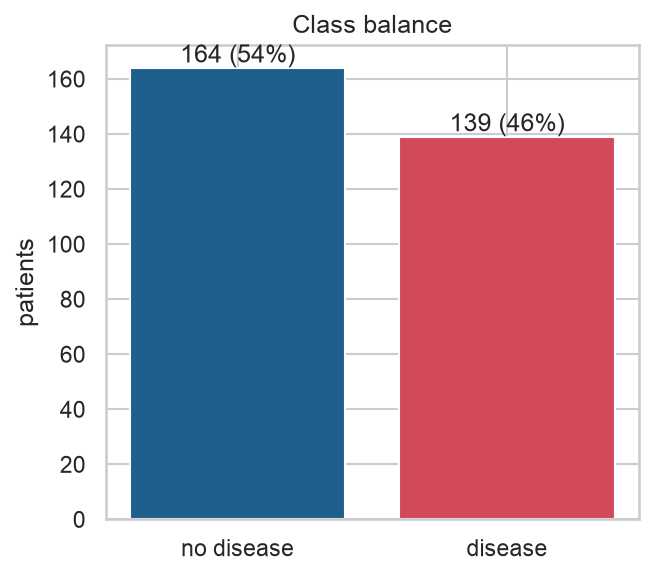

In [5]:
fig_dir = cfg.FIGURES_DIR / "eda"
display(Image(explore.fig_class_balance(df, fig_dir)))

## 4. Continuous features by outcome
Patients with disease are older, reach a lower maximum heart rate and show larger exercise-induced ST depression.

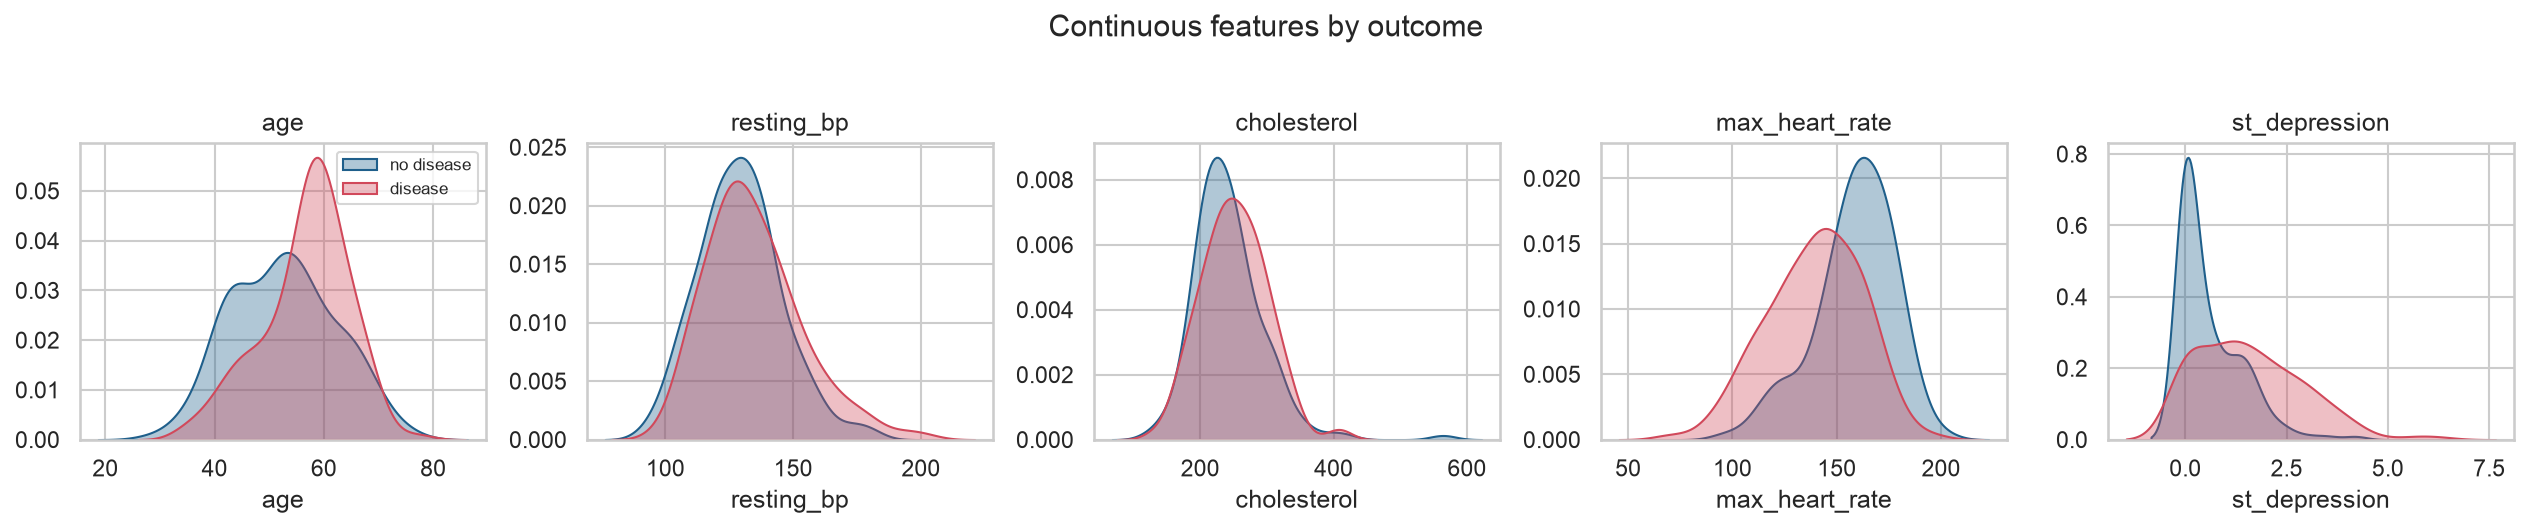

In [6]:
display(Image(explore.fig_continuous_distributions(df, fig_dir)))

## 5. Disease prevalence by category
Asymptomatic chest pain (type 4), a reversible thallium defect (7), exercise angina, a flat ST slope and more coloured vessels all raise the disease rate well above the overall 46 %.

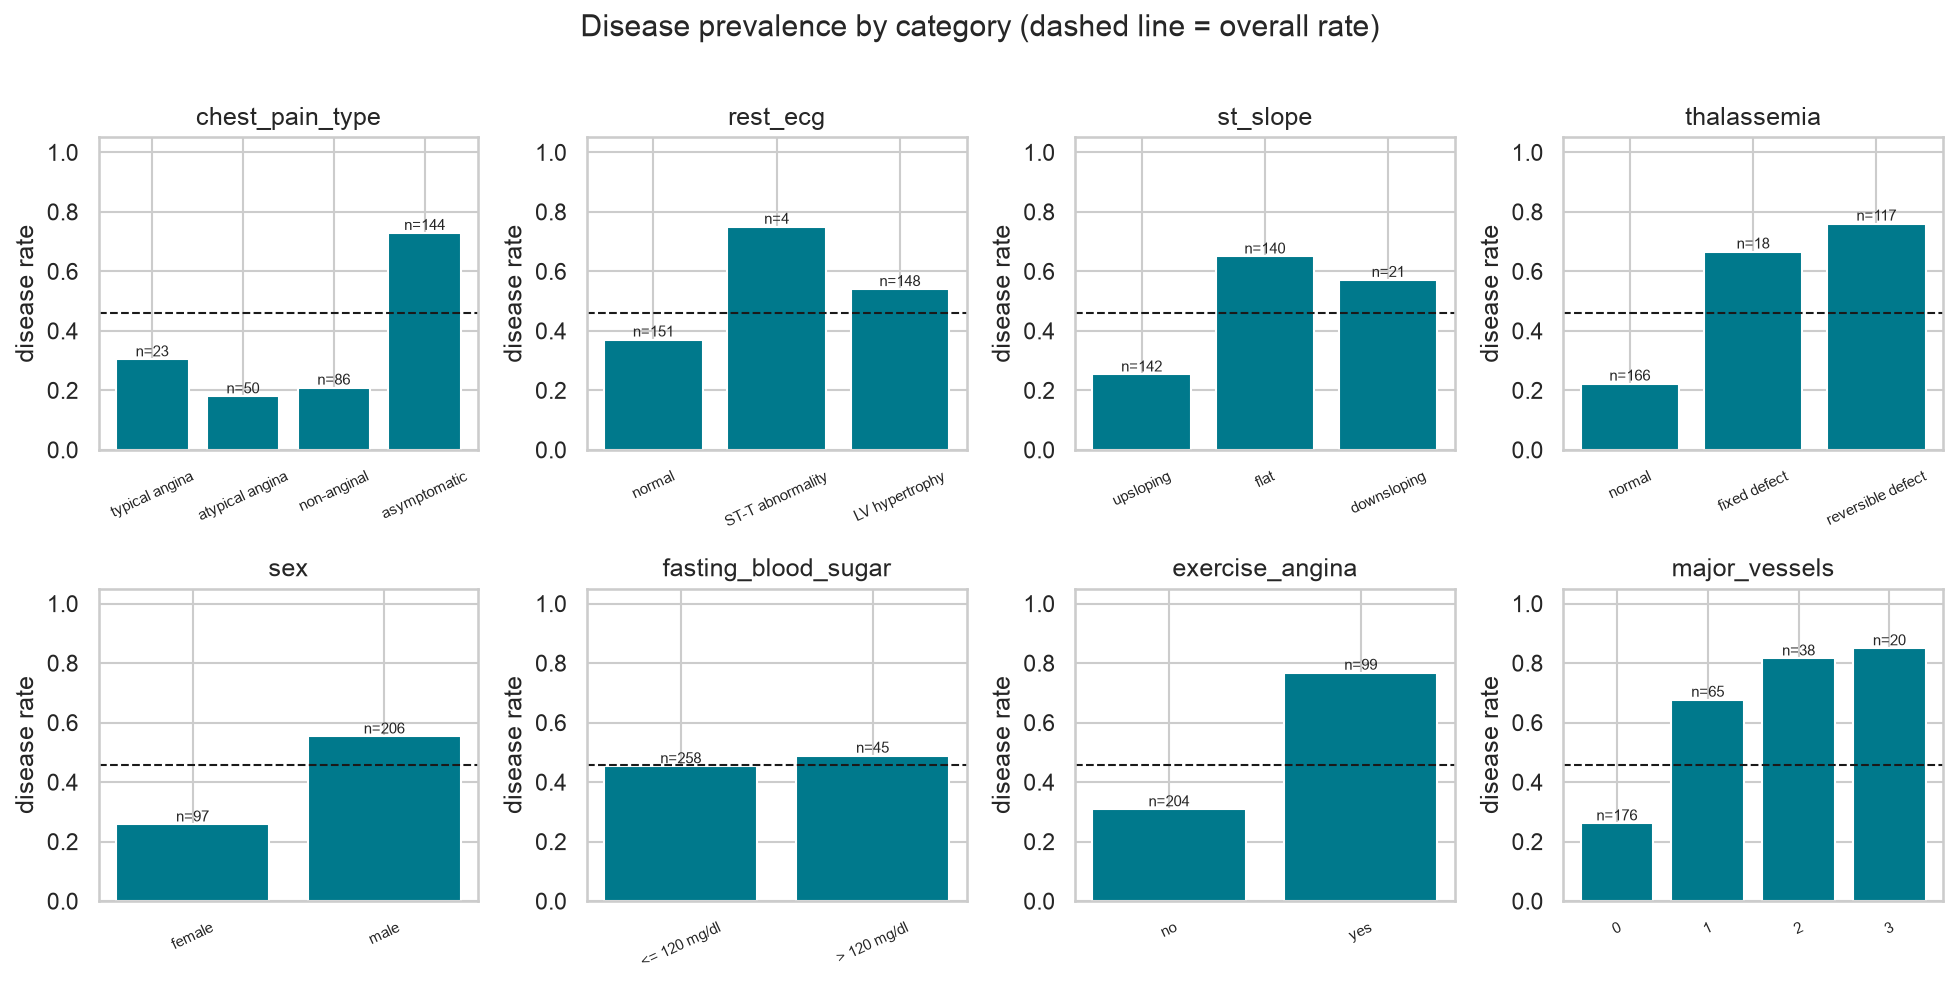

In [7]:
display(Image(explore.fig_categorical_prevalence(df, fig_dir)))

## 6. Correlation structure
Spearman correlation is used because several variables are ordinal. The strongest monotone relations with the target are `thalassemia`, `major_vessels`, `chest_pain_type`, `exercise_angina`, `max_heart_rate` and `st_depression`. Feature-feature correlations are moderate (|rho| < 0.6), so multicollinearity is not a concern for logistic regression.

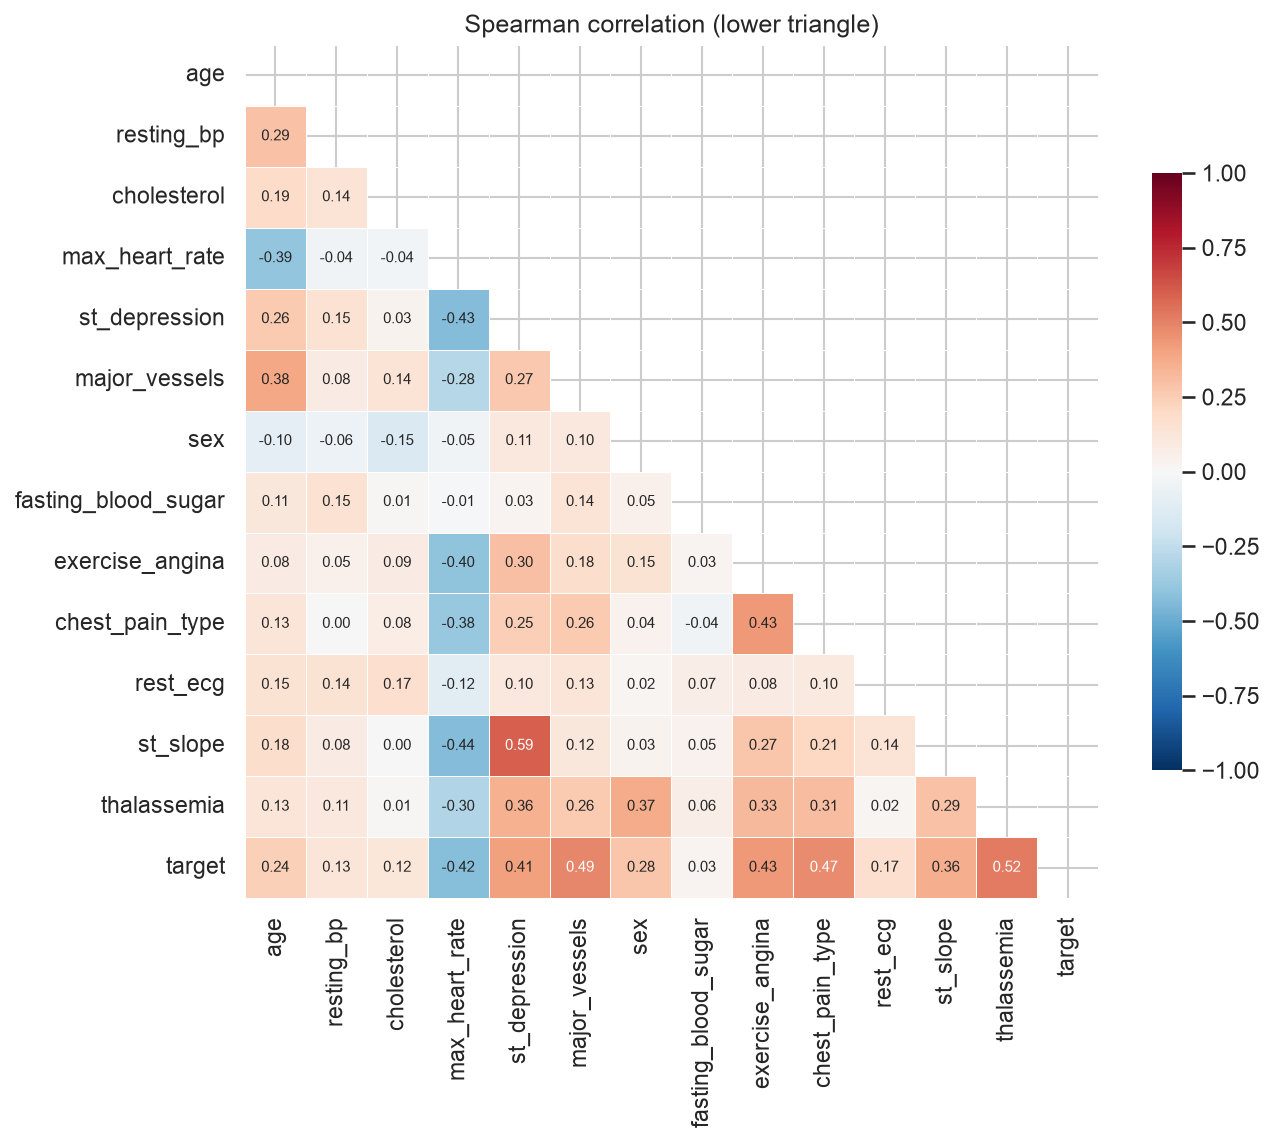

In [8]:
display(Image(explore.fig_correlation(df, fig_dir)))

In [9]:
corr = df.astype(float).corr(method="spearman")[cfg.TARGET].drop(cfg.TARGET)
corr.abs().sort_values(ascending=False).round(3).to_frame("|spearman rho| with target")

,|spearman rho| with target
thalassemia,0.522
major_vessels,0.489
chest_pain_type,0.472
exercise_angina,0.432
max_heart_rate,0.423
st_depression,0.413
st_slope,0.364
sex,0.277
age,0.237
rest_ecg,0.169


## 7. Chronotropic response
Maximum heart rate falls with age (dashed line = 220 - age). Diseased patients cluster *below* the healthy cloud at the same age, which motivates the engineered feature `hr_reserve_pct = max_heart_rate / (220 - age)`.

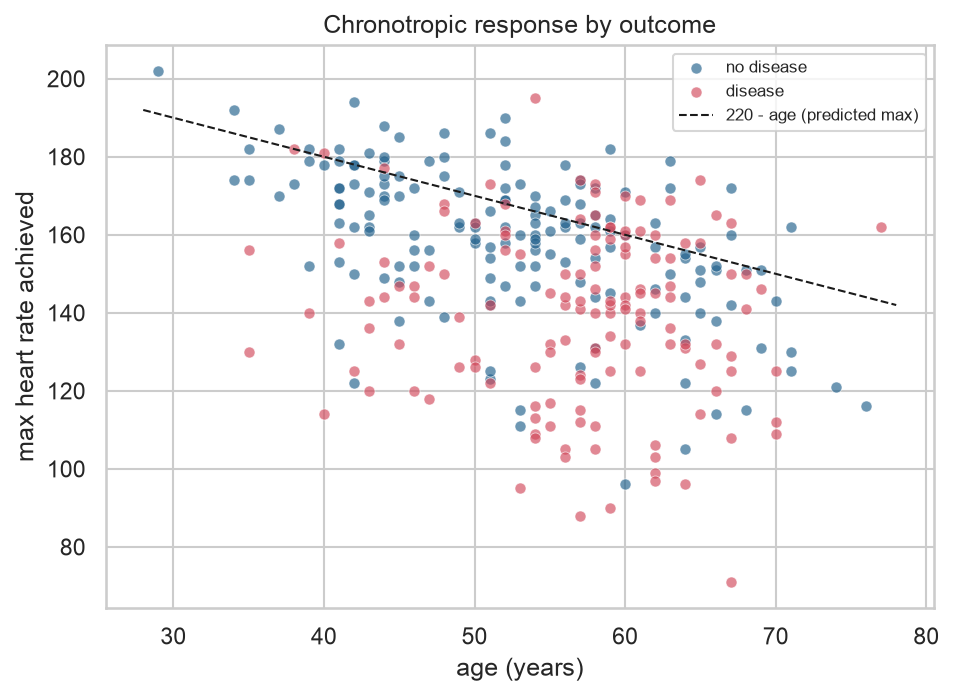

In [10]:
display(Image(explore.fig_age_hr_scatter(df, fig_dir)))

## 8. ST depression and slope
A depressed ST segment together with a flat or downsloping slope is the classic ischaemia pattern; this motivates `st_burden = st_depression x slope_weight`.

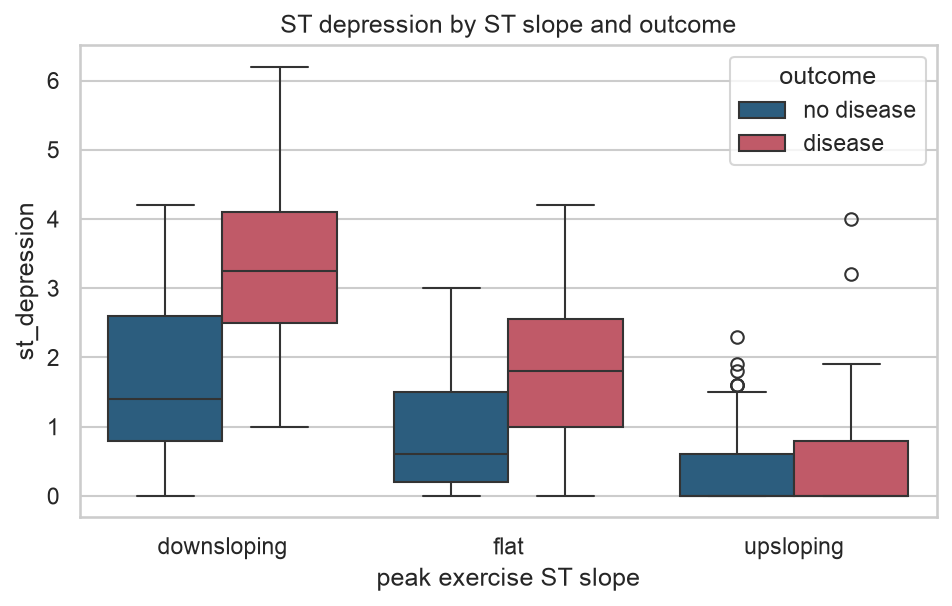

In [11]:
display(Image(explore.fig_st_depression_box(df, fig_dir)))

## 9. Take-aways for modelling

* Small (303 rows), clean, near-balanced tabular dataset: regularised linear models and small ensembles are appropriate; cross-validation must be repeated to get stable estimates.
* Six missing cells only: median / most-frequent imputation inside the pipeline is sufficient.
* Nominal codes (`chest_pain_type`, `rest_ecg`, `st_slope`, `thalassemia`) are one-hot encoded; continuous features are standardised; three engineered features add clinical prior knowledge.
* Strongest univariate signals: thallium result, number of vessels, chest-pain type, exercise angina, max heart rate, ST depression.

In [12]:
json.dumps(explore.profile(df)['top_correlates_with_target'], indent=2)

'{\n  "thalassemia": 0.522,\n  "major_vessels": 0.489,\n  "chest_pain_type": 0.472,\n  "exercise_angina": 0.432,\n  "max_heart_rate": 0.423,\n  "st_depression": 0.413\n}'